# 6. OSM data for GIS

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/06_gis.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/06_gis.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You get the OSM features of Monaco as GeoDataFrames, write the road network as OSM XML, and read the administrative areas. The module is `duckosm.gis`. [duckOSM for GIS users](https://khoshkhah.github.io/duckOSM/compare/for-gis-users/) compares each call with OSMnx, QuackOSM and osmium.

| Call | Result | OSMnx |
|---|---|---|
| `duckosm.gis.features` | OSM features as a GeoDataFrame | `features_from_place` |
| `duckosm.gis.to_osm_xml` | the network as an `.osm` file | `save_graph_xml` |
| `duckosm.gis.admin_boundaries` | the administrative areas as a GeoDataFrame | `geocode_to_gdf` |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:                       # duckosm is there: no install
    import duckosm         # the SDK
except ImportError:        # else install it with the extras of this notebook
    %pip install -q "duckosm[gis,viz]"
    import duckosm         # the SDK
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


In [2]:
net = duckosm.network("Monaco", modes=["driving"])    # get and build the driving network of Monaco (the OSM file stays beside it)
net                                                   # the card

cut: 34794 nodes, 5693 ways, 343 relations

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


## OSM features

`features` takes an area, an OSM file or a network. `tags` has the rules of OSMnx: `True` is any value, a text is one value, a list is one of the values. The keys are joined with OR.

In [3]:
buildings = duckosm.gis.features(net, tags={"building": True})    # each feature with the tag building
len(buildings), buildings.geom_type.value_counts().to_dict()       # the number of buildings, by geometry type

(1258, {'Polygon': 1258})

In [4]:
food = duckosm.gis.features(net, tags={"amenity": ["cafe", "restaurant", "bar"]})    # three values of one tag
food.amenity.value_counts()                                                          # the features of each value

amenity
restaurant    124
cafe           27
bar            21
Name: count, dtype: int64

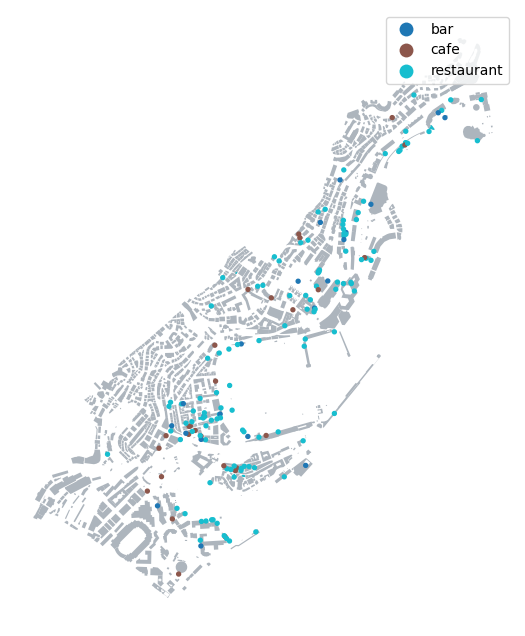

In [5]:
ax = buildings.plot(color="#adb5bd", figsize=(8, 8))                  # the buildings in grey
food.plot(ax=ax, column="amenity", legend=True, markersize=8)         # the cafes, restaurants and bars on them
ax.set_axis_off()                                                     # no axes

In [6]:
food[["feature_id", "amenity", "geometry"]].head()    # the first rows: feature_id, the tag column and the geometry

,feature_id,amenity,geometry
0,node/10005045289,cafe,POINT (7.42245 43.73105)
1,node/10025656390,restaurant,POINT (7.42693 43.73688)
2,node/10025843517,restaurant,POINT (7.42194 43.73674)
3,node/10025852089,bar,POINT (7.42275 43.73699)
4,node/10025852090,restaurant,POINT (7.42251 43.73696)


## The network as OSM XML

`to_osm_xml` writes one `<way>` for each road, with the `edge_id` as its id, and the OSM nodes of the road. The tags `duckosm:osm_id` and `duckosm:edge_id` give the OSM way and the edge.

In [7]:
import xml.etree.ElementTree as ET                                     # to read the file back

osm = duckosm.gis.to_osm_xml(net.driving, "out/monaco.osm")             # the OSM XML file
root = ET.parse(osm["path"]).getroot()                                 # read it back
osm, len(root.findall("node")), len(root.findall("way"))               # the numbers, and the nodes and ways in the file

({'path': PosixPath('out/monaco.osm'), 'nodes': 5933, 'ways': 1997},
 5933,
 1997)

In [8]:
{t.get("k"): t.get("v") for t in root.find("way").iter("tag")}         # the tags of the first way

{'highway': 'service',
 'oneway': 'no',
 'lanes': '2',
 'lanes:forward': '1',
 'lanes:backward': '1',
 'maxspeed': '20',
 'duckosm:osm_id': '177052163',
 'duckosm:edge_id': '2214154189574909'}

## Administrative areas

`admin_boundaries` adds the table `admin_boundaries` to the database when it has none, and gives each OSM administrative area with its level.

In [9]:
admin = duckosm.gis.admin_boundaries(net)                     # the administrative areas
admin.drop(columns="geometry")                                # the table, without the geometry

,osm_id,name,name_en,admin_level,parent_osm_id
0,1124039,Monaco,Monaco,2,<NA>
1,2220322,Monaco,Monaco,8,1124039
2,2220206,Fontvieille,None,10,2220322
3,5986473,Jardin Exotique,None,10,2220322
4,2221178,La Condamine,None,10,2220322
5,5986436,La Rousse,None,10,2220322
6,5986437,Larvotto,None,10,2220322
7,5986474,Les Monegetti,None,10,2220322
8,2220207,Monaco-Ville,None,10,2220322
9,5986438,Monte-Carlo,None,10,2220322


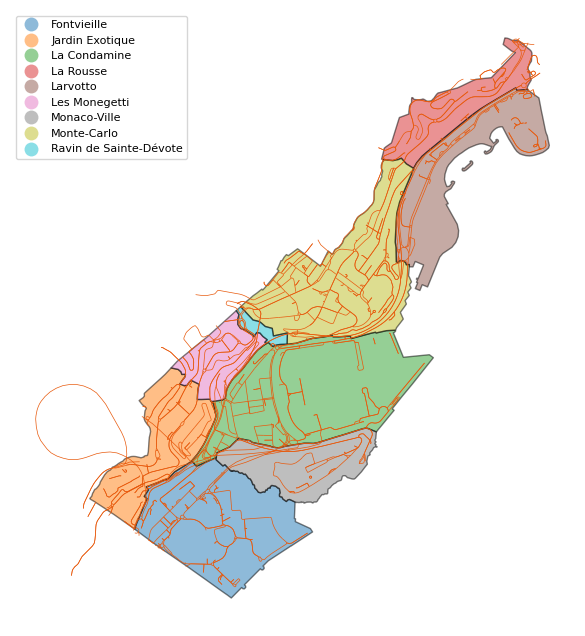

In [10]:
quarters = admin[admin.admin_level == 10]                     # level 10: the quarters (level 2, the country, has the sea too)
ax = quarters.plot(column="name", alpha=0.5, edgecolor="black", legend=True, figsize=(8, 8),
                   legend_kwds={"loc": "upper left", "fontsize": 8})    # each quarter in its own color
net.edges().plot(ax=ax, color="#e8590c", linewidth=0.5)       # the roads on them
ax.set_axis_off()                                             # no axes